# Member 3 — Classification Track, Part B: Gradient Boosting (Adult / Census Income)

**Review 2 scope (Member 3):** one Part-B algorithm — **Gradient Boosting** — plus the consolidated 10-algorithm
table and final model selection (`member3_classification_A2_A3.ipynb`).

- Data: the shared `adult_prep.prepare()` pipeline (same cleaning, engineered features, stratified 80:20 split and
  train-only encoder/scaler as Review 1 Part A), so the model is scored on the same 9,035 test rows as every other
  classifier. The step-by-step preprocessing walkthrough is in `classification_member2.ipynb`, section 1.
- Same protocol as the other Part B models: balanced sample weights for the 75/25 imbalance, stratified 5-fold
  `GridSearchCV` on weighted F1, baseline vs tuned, 5-fold CV of the tuned model.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)

from adult_prep import prepare, RANDOM_STATE

np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'

RESULTS_DIR = Path('../results/classification')
MODELS_DIR = Path('../models/classification')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load the shared preprocessed split

In [2]:
data = prepare('../data/raw/adult')
X_train, X_test = data['X_train'], data['X_test']
y_train, y_test = data['y_train'], data['y_test']
class_names = list(data['target_le'].classes_)
print('train:', X_train.shape, '| test:', X_test.shape)
print('share >50K  train: %.4f | test: %.4f' % (y_train.mean(), y_test.mean()))

train: (36140, 89) | test: (9035, 89)
share >50K  train: 0.2480 | test: 0.2479


**Check.** 36,140 / 9,035 rows, 89 features, identical 24.8% `>50K` share — the same split as every other model.

In [3]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
# balanced sample weights: each >50K row counts ~3x, the same imbalance treatment as the other nine models
sw_train = compute_sample_weight('balanced', y_train)

def score(model, X, y_true):
    """All required metrics for one fitted model on one data set."""
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'accuracy': accuracy_score(y_true, pred),
        'precision_weighted': precision_score(y_true, pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, pred, average='weighted'),
        'f1_weighted': f1_score(y_true, pred, average='weighted'),
        'f1_macro': f1_score(y_true, pred, average='macro'),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'roc_auc': roc_auc_score(y_true, proba),
    }

results = {}

## 2. Gradient Boosting

Boosting builds shallow trees **one after another**. Each new tree is fitted to the **gradient of the log-loss**
(roughly, the remaining errors) of the current ensemble, and its output is added after being shrunk by the
`learning_rate`. Many small corrections add up to a strong model, so boosting mainly **reduces bias**
(Random Forest / Bagging average independent trees and mainly reduce variance).

- `n_estimators` and `learning_rate` trade off: a smaller rate needs more trees.
- `max_depth` sets how many features one tree can combine (depth 3 = interactions of up to 3 features).
- `GradientBoostingClassifier` has no `class_weight`, so the balanced **sample weights** are passed to `fit`.

### 2.1 Baseline (sklearn defaults: 100 trees, `learning_rate=0.1`, `max_depth=3`)

In [4]:
gb_base = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_base.fit(X_train, y_train, sample_weight=sw_train)
results['Gradient Boosting (base)'] = score(gb_base, X_test, y_test)
pd.Series(results['Gradient Boosting (base)']).round(4)

accuracy              0.8199
precision_weighted    0.8567
recall_weighted       0.8199
f1_weighted           0.8290
f1_macro              0.7860
balanced_accuracy     0.8302
roc_auc               0.9171
dtype: float64

### 2.2 Tuning `n_estimators`, `learning_rate` and `max_depth`

Stratified 5-fold `GridSearchCV` on the training set only, scored on weighted F1. The sample weights are routed
through `fit`, so each fold uses the weights of its own training rows. 12 settings x 5 folds = 60 fits.

In [5]:
gb_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
}
search = GridSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE), gb_grid, scoring='f1_weighted',
                      cv=CV, n_jobs=-1, return_train_score=True)
search.fit(X_train, y_train, sample_weight=sw_train)
print('best params:', search.best_params_)
print('best CV weighted F1: %.4f' % search.best_score_)

grid_table = (pd.DataFrame(search.cv_results_)
              [['param_n_estimators', 'param_learning_rate', 'param_max_depth',
                'mean_train_score', 'mean_test_score', 'std_test_score']]
              .sort_values('mean_test_score', ascending=False).reset_index(drop=True))
display(grid_table.round(4))

best params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300}
best CV weighted F1: 0.8426


,param_n_estimators,param_learning_rate,param_max_depth,mean_train_score,mean_test_score,std_test_score
0,300,0.05,5,0.8617,0.8426,0.0049
1,200,0.05,5,0.8568,0.8424,0.0046
2,200,0.10,5,0.8663,0.8421,0.0045
3,100,0.10,5,0.8568,0.8421,0.0049
4,300,0.10,5,0.8728,0.8417,0.0042
5,300,0.10,3,0.8522,0.8415,0.0044
6,200,0.10,3,0.8470,0.8396,0.0036
7,300,0.05,3,0.8435,0.8375,0.0036
8,100,0.05,5,0.8475,0.8372,0.0029
9,100,0.10,3,0.8394,0.8347,0.0033


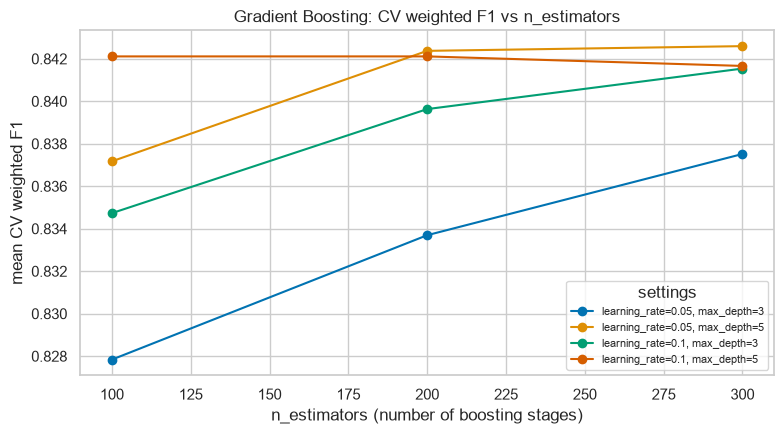

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (lr, depth), grp in grid_table.groupby(['param_learning_rate', 'param_max_depth']):
    grp = grp.sort_values('param_n_estimators')
    ax.plot(grp['param_n_estimators'], grp['mean_test_score'], marker='o', label=f'learning_rate={lr}, max_depth={depth}')
ax.set_title('Gradient Boosting: CV weighted F1 vs n_estimators')
ax.set_xlabel('n_estimators (number of boosting stages)')
ax.set_ylabel('mean CV weighted F1')
ax.legend(title='settings', fontsize=8)
save_fig('m3_gb_tuning_curve.png')
plt.show()

**Observation.**
- **Depth 5 beats depth 3** at every learning rate and size: deeper trees capture interactions (e.g. married AND
  degree AND age) that depth-3 trees need many more stages to approximate.
- **Rate and size trade off:** `learning_rate=0.05` with 300 trees (0.8426) ties `learning_rate=0.1` with 100 trees
  (0.8421). Halving the step size needs roughly three times the trees.
- **Early overfitting at the top end:** `learning_rate=0.1, max_depth=5, 300 trees` has the highest train score
  (0.873) but a lower CV score than smaller settings. All top five settings lie within 0.001 CV F1, so the choice
  among them matters little. Best: `learning_rate=0.05, max_depth=5, n_estimators=300` (CV 0.8426).

In [7]:
gb = search.best_estimator_
results['Gradient Boosting (tuned)'] = score(gb, X_test, y_test)
before_after = pd.DataFrame(results).T
before_after.loc['change (tuned - base)'] = before_after.loc['Gradient Boosting (tuned)'] - before_after.loc['Gradient Boosting (base)']
display(before_after.round(4))

tuning_rows = [{'model': 'Gradient Boosting', 'metric': m, 'base': results['Gradient Boosting (base)'][m],
                'tuned': results['Gradient Boosting (tuned)'][m],
                'change': results['Gradient Boosting (tuned)'][m] - results['Gradient Boosting (base)'][m],
                'best_params': str(search.best_params_)}
               for m in ['accuracy', 'f1_weighted', 'f1_macro', 'roc_auc']]
pd.DataFrame(tuning_rows).to_csv(RESULTS_DIR / 'partB_member3_tuning_results.csv', index=False)

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
Gradient Boosting (base),0.8199,0.8567,0.8199,0.8290,0.786,0.8302,0.9171
Gradient Boosting (tuned),0.8372,0.8669,0.8372,0.8446,0.804,0.8442,0.9260
change (tuned - base),0.0173,0.0103,0.0173,0.0157,0.018,0.0140,0.0090


**Observation.** Tuning improves **every metric** on the held-out test set: accuracy +0.017, weighted F1 +0.016,
macro F1 +0.018, balanced accuracy +0.014 and ROC-AUC +0.009 (0.917 -> **0.926**). The parameters were chosen by CV on
the training set only, so the gain is an honest estimate.

### 2.3 Staged test score

`staged_predict_proba` gives the model after each boosting stage, showing how ROC-AUC on the test set grows as trees
are added (diagnostic only — the number of trees was chosen by CV).

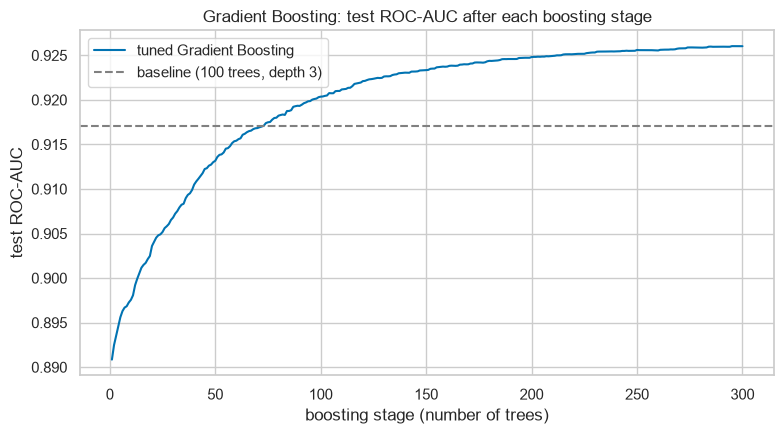

ROC-AUC after 1, 10, 50, all stages: [0.8908, 0.8976, 0.9132, 0.926]


In [8]:
staged_auc = [roc_auc_score(y_test, p[:, 1]) for p in gb.staged_predict_proba(X_test)]
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(staged_auc) + 1), staged_auc, label='tuned Gradient Boosting')
plt.axhline(results['Gradient Boosting (base)']['roc_auc'], color='grey', ls='--', label='baseline (100 trees, depth 3)')
plt.title('Gradient Boosting: test ROC-AUC after each boosting stage')
plt.xlabel('boosting stage (number of trees)')
plt.ylabel('test ROC-AUC')
plt.legend()
save_fig('m3_gb_staged_auc.png')
plt.show()
print('ROC-AUC after 1, 10, 50, all stages: %s' % [round(staged_auc[i - 1], 4) for i in (1, 10, 50, len(staged_auc))])

**Observation.** A single depth-5 tree already ranks people well (ROC-AUC 0.891). Adding stages keeps improving the
ranking — 0.898 after 10 trees, 0.913 after 50, 0.926 after 300 — with no drop at the end, so 300 small steps at
`learning_rate=0.05` do not overfit the ranking.

### 2.4 Feature importance

Impurity-based importance of the tuned model, with one-hot columns summed back to their original feature.

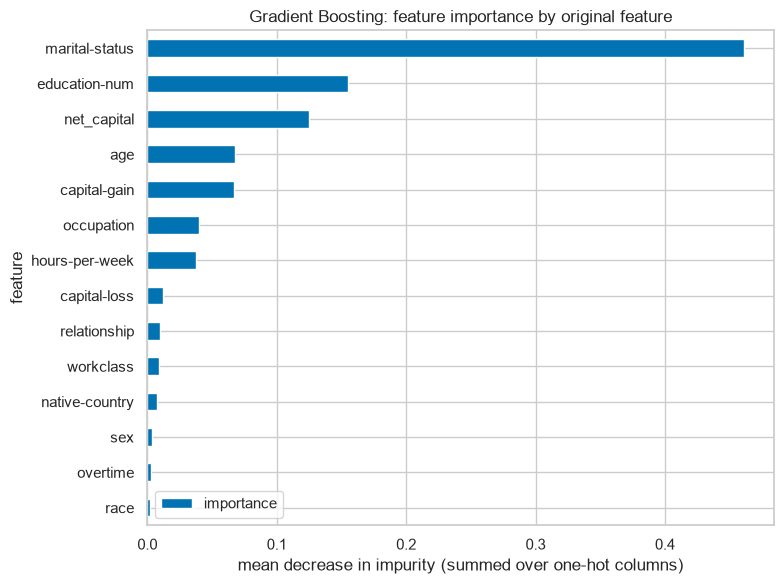

{'marital-status': 0.461, 'education-num': 0.155, 'net_capital': 0.125, 'age': 0.068, 'capital-gain': 0.067, 'occupation': 0.04, 'hours-per-week': 0.037, 'capital-loss': 0.012, 'relationship': 0.01, 'workclass': 0.009, 'native-country': 0.008, 'sex': 0.004, 'overtime': 0.003, 'race': 0.002}


In [9]:
CAT_PREFIXES = ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
def base_feature(col):
    return next((p for p in CAT_PREFIXES if col.startswith(p + '_')), col)

imp = pd.Series(gb.feature_importances_, index=X_train.columns).groupby(base_feature).sum().sort_values()
ax = imp.plot.barh(figsize=(8, 6), color=sns.color_palette('colorblind')[0], label='importance')
ax.set_title('Gradient Boosting: feature importance by original feature')
ax.set_xlabel('mean decrease in impurity (summed over one-hot columns)')
ax.set_ylabel('feature')
ax.legend()
save_fig('m3_gb_feature_importance.png')
plt.show()
print(imp.sort_values(ascending=False).round(3).to_dict())

**Observation.** Boosting concentrates on few features: `marital-status` 0.46, `education-num` 0.16, the engineered
**`net_capital` 0.13**, `age` 0.07, `capital-gain` 0.07. `net_capital` ranking third shows the Review 1 feature
engineering is used heavily. `relationship` gets only 0.01: it carries nearly the same information as
`marital-status` (husband / wife = married), and once boosting splits on one, the other adds little — a known
effect of impurity importance with correlated features.

## 3. Evaluation of the tuned model

### 3.1 Confusion matrix and per-class report

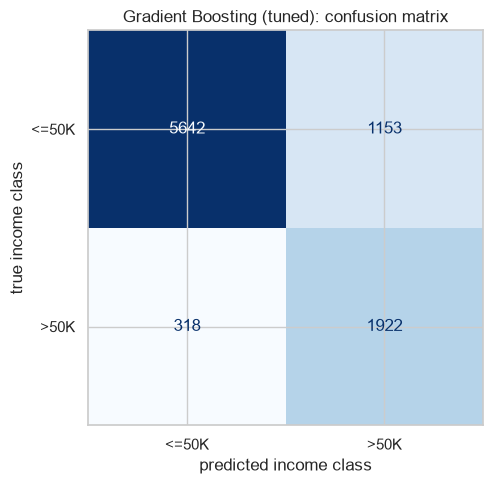

              precision    recall  f1-score   support

       <=50K      0.947     0.830     0.885      6795
        >50K      0.625     0.858     0.723      2240

    accuracy                          0.837      9035
   macro avg      0.786     0.844     0.804      9035
weighted avg      0.867     0.837     0.845      9035



In [10]:
pred = gb.predict(X_test)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Gradient Boosting (tuned): confusion matrix')
ax.set_xlabel('predicted income class')
ax.set_ylabel('true income class')
save_fig('partB_member3_confusion_matrix.png')
plt.show()
print(classification_report(y_test, pred, target_names=class_names, digits=3))

**Observation.** With balanced weights the model catches **86% of `>50K` people** (recall 0.858) but 37% of its `>50K`
predictions are false alarms (precision 0.625); 83% of `<=50K` people are classified correctly. Most errors are
`<=50K` people predicted as `>50K` — the price of not missing high earners.

### 3.2 ROC curve

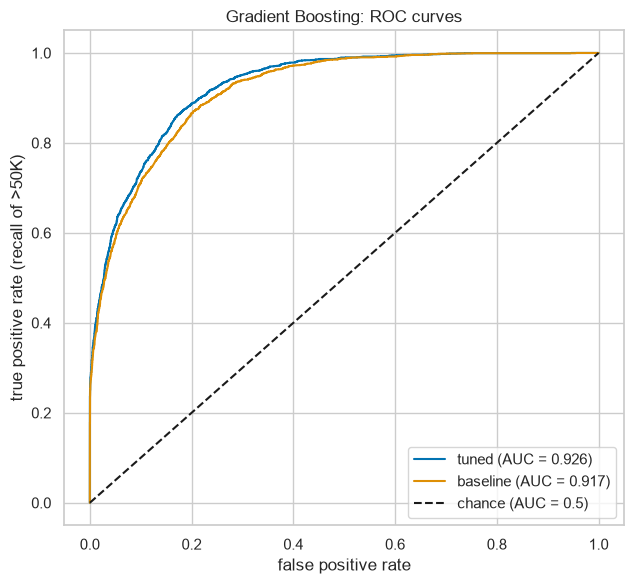

In [11]:
fpr, tpr, _ = roc_curve(y_test, gb.predict_proba(X_test)[:, 1])
fpr_b, tpr_b, _ = roc_curve(y_test, gb_base.predict_proba(X_test)[:, 1])
plt.figure(figsize=(6.5, 6))
plt.plot(fpr, tpr, label=f"tuned (AUC = {results['Gradient Boosting (tuned)']['roc_auc']:.3f})")
plt.plot(fpr_b, tpr_b, label=f"baseline (AUC = {results['Gradient Boosting (base)']['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='chance (AUC = 0.5)')
plt.title('Gradient Boosting: ROC curves')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate (recall of >50K)')
plt.legend(loc='lower right')
save_fig('partB_member3_roc_curve.png')
plt.show()

### 3.3 5-fold cross-validation of the tuned model

A fresh stratified 5-fold CV of the tuned settings on the training set (with sample weights) — not just the
grid-search score — so mean and spread can be compared with the other models.

In [12]:
cv = cross_validate(gb, X_train, y_train, cv=CV, n_jobs=-1, params={'sample_weight': sw_train},
                    scoring=['accuracy', 'f1_weighted', 'roc_auc'])
cv_table = pd.DataFrame([{'model': 'Gradient Boosting',
    'cv_accuracy_mean': cv['test_accuracy'].mean(), 'cv_accuracy_std': cv['test_accuracy'].std(),
    'cv_f1_weighted_mean': cv['test_f1_weighted'].mean(), 'cv_f1_weighted_std': cv['test_f1_weighted'].std(),
    'cv_roc_auc_mean': cv['test_roc_auc'].mean(), 'cv_roc_auc_std': cv['test_roc_auc'].std()}]).set_index('model')
display(cv_table.round(4))
cv_table.to_csv(RESULTS_DIR / 'partB_member3_cv_results.csv')

,cv_accuracy_mean,cv_accuracy_std,cv_f1_weighted_mean,cv_f1_weighted_std,cv_roc_auc_mean,cv_roc_auc_std
model,,,,,,
Gradient Boosting,0.8341,0.0031,0.8419,0.0029,0.9272,0.0036


**Observation.** 5-fold CV of the tuned model: accuracy 0.834 ± 0.003, weighted F1 0.842 ± 0.003, ROC-AUC
0.927 ± 0.004. The CV means match the test scores (0.837 / 0.845 / 0.926), so the result is stable and not a lucky
split.

## 4. Save results and model

In [13]:
part_b = pd.DataFrame({'Gradient Boosting': results['Gradient Boosting (tuned)']}).T
part_b.index.name = 'model'
part_b.to_csv(RESULTS_DIR / 'partB_member3_model_comparison.csv')
joblib.dump(gb, MODELS_DIR / 'gradient_boosting.pkl', compress=3)
display(part_b.round(4))
print('saved: partB_member3_model_comparison.csv, partB_member3_tuning_results.csv, '
      'partB_member3_cv_results.csv, models/classification/gradient_boosting.pkl')

,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro,balanced_accuracy,roc_auc
model,,,,,,,
Gradient Boosting,0.8372,0.8669,0.8372,0.8446,0.804,0.8442,0.926


saved: partB_member3_model_comparison.csv, partB_member3_tuning_results.csv, partB_member3_cv_results.csv, models/classification/gradient_boosting.pkl


## 5. Summary

| | Accuracy | Weighted F1 | Macro F1 | Balanced acc. | ROC-AUC |
|---|---|---|---|---|---|
| Baseline (100 trees, lr 0.1, depth 3) | 0.820 | 0.829 | 0.786 | 0.830 | 0.917 |
| **Tuned** (300 trees, lr 0.05, depth 5) | **0.837** | **0.845** | **0.804** | **0.844** | **0.926** |

- Same split and preprocessing as all other classifiers; balanced sample weights; stratified 5-fold `GridSearchCV`
  and 5-fold CV of the tuned model.
- Tuning improved every metric. Gradient Boosting has the **highest ROC-AUC** of the ten classifiers (see the A2
  notebook).
- **Why class weighting matters:** the first version of this notebook trained without weights and reported weighted
  F1 0.860 — but it caught only 62% of `>50K` people (balanced accuracy 0.78). Weighted F1 is dominated by the
  majority class, so an unweighted model looks better on it while being worse on the minority class. Using the same
  weighting as the other nine models keeps the A2 comparison fair.
- Saved: `results/classification/partB_member3_model_comparison.csv`, `partB_member3_tuning_results.csv`,
  `partB_member3_cv_results.csv`, plots `m3_gb_*.png` / `partB_member3_*.png`,
  `models/classification/gradient_boosting.pkl`.